# Клиентская аналитика интернет-магазина

Пет-проект: полный цикл анализа — от сырой выгрузки до выводов и рекомендаций.

Магазин товаров для дома работает два года (2024–2025) и привлекает клиентов из пяти каналов.
Руководство видит рост выручки, но не понимает, за счёт чего он происходит: приходят новые клиенты
или возвращаются старые, какие каналы окупаются, кого из клиентов можно удержать.

**Вопросы, на которые отвечает анализ**

1. Можно ли доверять выгрузке и что в ней нужно починить?
2. За счёт чего растёт выручка — новых клиентов или повторных покупок?
3. Как быстро магазин теряет клиентов и есть ли различия между когортами?
4. На какие группы делятся клиенты и где сосредоточены деньги?
5. Какие каналы привлечения окупаются, а какие работают в убыток?

**Инструменты:** PostgreSQL, SQLAlchemy, pandas, NumPy, SciPy, seaborn, matplotlib.

**План**

1. [Подключение к базе](#1.-Подключение-к-базе)
2. [Качество данных](#2.-Качество-данных)
3. [Ключевые метрики](#3.-Ключевые-метрики)
4. [Когортный анализ удержания](#4.-Когортный-анализ-удержания)
5. [RFM-сегментация](#5.-RFM-сегментация)
6. [Экономика каналов привлечения](#6.-Экономика-каналов-привлечения)
7. [A/B-тест реактивации](#7.-A/B-тест-реактивации)
8. [Выводы и рекомендации](#8.-Выводы-и-рекомендации)

## Данные

Витрина собрана в PostgreSQL из выгрузки интернет-магазина. Данные синтетические: их генерирует
скрипт `scripts/generate_data.py`, поэтому проект воспроизводится целиком несколькими командами.

| Таблица | Содержание |
|---|---|
| `customers` | клиент: дата регистрации, канал привлечения, город, устройство, подписка |
| `products` | товар: категория, цена, себестоимость |
| `orders` | заказ: клиент, дата, статус, способ оплаты, сумма |
| `order_items` | позиция заказа: товар, количество, цена, скидка |
| `marketing_spend` | расходы на канал по месяцам |
| `ab_experiment` | распределение клиентов по группам A/B-теста |

Связи: `orders.customer_id → customers.customer_id`, `order_items.order_id → orders.order_id`,
`order_items.product_id → products.product_id`.

## Настройка окружения

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display

BASE_DIR = os.path.join('..')
SQL_DIR = os.path.join(BASE_DIR, 'sql')

# Параметры подключения к PostgreSQL лежат в scripts/db.py и читаются из .env
sys.path.insert(0, os.path.abspath(os.path.join(BASE_DIR, 'scripts')))
from db import describe_connection, get_engine
IMAGES_DIR = os.path.join(BASE_DIR, 'images')
os.makedirs(IMAGES_DIR, exist_ok=True)

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110,
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', ' '))

MAIN = '#2E86AB'
ACCENT = '#E4572E'
GOOD = '#3BB273'
MUTED = '#C9CED6'


def run_sql_file(name, conn):
    """Выполняет запрос из файла в папке sql/ и возвращает результат как DataFrame."""
    with open(os.path.join(SQL_DIR, name), encoding='utf-8') as f:
        query = f.read()
    return pd.read_sql(query, conn)


def to_float(df, *columns):
    """PostgreSQL возвращает NUMERIC как Decimal — приводим к float для расчётов."""
    for column in columns:
        df[column] = df[column].astype(float)
    return df


def save_fig(fig, name):
    fig.savefig(os.path.join(IMAGES_DIR, name), bbox_inches='tight', facecolor='white')


def thousands(x, pos=None):
    return f'{x:,.0f}'.replace(',', ' ')


def millions(x, pos=None):
    text = f'{x / 1e6:,.1f}'.replace(',', ' ').rstrip('0').rstrip('.')
    return f'{text} млн'

## 1. Подключение к базе

Данные лежат в PostgreSQL. Параметры подключения читаются из `.env` через модуль
[`scripts/db.py`](../scripts/db.py), поэтому в ноутбуке нет ни пароля, ни захардкоженного хоста.

Если база ещё не собрана, выполните в корне проекта: `python scripts/generate_data.py`,
затем `python scripts/build_database.py`.

In [2]:
engine = get_engine()

try:
    with engine.connect() as test_connection:
        server_version = pd.read_sql('SELECT version() AS v', test_connection)['v'][0]
except Exception as error:
    raise SystemExit(
        f'Не удалось подключиться к базе ({describe_connection()}):\n  {error}\n\n'
        'Проверьте, что PostgreSQL запущен, и выполните:\n'
        '  python scripts/generate_data.py\n'
        '  python scripts/build_database.py'
    )

print(f'Подключение: {describe_connection()}')
print(server_version.split(' on ')[0])

Подключение: postgres@localhost:5432/shop
PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04.1)


In [3]:
# Что лежит в базе: таблицы с сырыми данными и представления с очищенными
objects = pd.read_sql("""
    SELECT table_type, table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
    ORDER BY table_type, table_name
""", engine)

objects['rows'] = objects['table_name'].map(
    lambda name: pd.read_sql(f'SELECT COUNT(*) AS n FROM {name}', engine)['n'][0]
)
objects

,table_type,table_name,rows
0,BASE TABLE,ab_experiment,2998
1,BASE TABLE,customers,4200
2,BASE TABLE,marketing_spend,120
3,BASE TABLE,order_items,8165
4,BASE TABLE,orders,4598
5,BASE TABLE,products,320
6,VIEW,customers_clean,4200
7,VIEW,order_items_clean,8151
8,VIEW,orders_clean,4543
9,VIEW,sales,7447


В базе шесть таблиц с сырыми данными и четыре представления с очищенными.
Представление `sales` — основная витрина: одна строка на позицию выполненного заказа
с посчитанной выручкой и маржой.

In [4]:
period = pd.read_sql(
    'SELECT MIN(order_date) AS first_order, MAX(order_date) AS last_order FROM orders_clean',
    engine,
)
print(f'Период данных: {period.first_order[0]} — {period.last_order[0]}')

pd.read_sql('SELECT * FROM sales LIMIT 5', engine)

Период данных: 2024-01-01 — 2025-12-31


,order_id,customer_id,order_date,order_month,order_month_start,order_number,payment_method,channel,city,signup_month,is_subscribed,product_id,category,quantity,discount,item_revenue,item_cost,item_margin
0,100001,1,2024-01-01,2024-01,2024-01-01,1,cash_on_delivery,referral,Санкт-Петербург,2024-01,1,18,Кофе и чай,1,0.15,2 100.07,1 268.72,831.35
1,105139,1,2025-10-23,2025-10,2025-10-01,2,card,referral,Санкт-Петербург,2024-01,1,93,Посуда,1,0.10,4 677.50,3 392.91,1 284.59
2,105139,1,2025-10-23,2025-10,2025-10-01,2,card,referral,Санкт-Петербург,2024-01,1,42,Техника для дома,2,0.10,7 976.43,4 957.88,3 018.55
3,100005,2,2024-03-11,2024-03,2024-03-01,3,card,referral,Новосибирск,2024-01,1,96,Техника для дома,1,0.00,5 538.65,2 435.73,3 102.92
4,100005,2,2024-03-11,2024-03,2024-03-01,3,card,referral,Новосибирск,2024-01,1,263,Декор,1,0.00,3 923.49,2 052.89,1 870.60


## 2. Качество данных

Перед расчётом метрик проверяем выгрузку на типичные дефекты. Запрос
[`sql/02_data_quality.sql`](../sql/02_data_quality.sql) собирает проверки в один чек-лист.

In [5]:
quality = run_sql_file('02_data_quality.sql', engine)
quality

,check_name,issues,comment
0,Дубли строк в orders,55,критично: завышает число заказов
1,Статусы в разном регистре,7,критично: ломает фильтрацию по статусу
2,Позиции без заказа,0,критично: нарушает связь таблиц
3,Выбросы в quantity (> 20 шт.),14,критично: искажает выручку
4,Заказы раньше даты регистрации,0,критично: ломает когортный анализ
5,Пропуски в customers.city,168,некритично: поле не используется в метриках
6,Пропуски в customers.device,84,некритично: поле не используется в метриках


Нашлись три дефекта, которые исказили бы метрики:

- **дубли строк в `orders`** — часть заказов попала в выгрузку дважды;
- **статусы в разном регистре** (`DELIVERED`, ` delivered `) — фильтр `status = 'delivered'` их потеряет;
- **выбросы в `quantity`** — десятки позиций с количеством в сотни штук, похоже на ошибку ввода.

Пропуски в городе и устройстве некритичны: в метриках эти поля не участвуют.

Чинить данные удобнее один раз на уровне представлений, а не в каждом запросе. Это делает
[`sql/03_clean_views.sql`](../sql/03_clean_views.sql): убирает дубли, приводит статусы к нижнему регистру,
отсекает выбросы и собирает витрину `sales` только из выполненных заказов.

In [6]:
comparison = pd.read_sql("""
    SELECT 'orders (сырая таблица)'  AS source, COUNT(*) AS rows FROM orders
    UNION ALL
    SELECT 'orders_clean',             COUNT(*) FROM orders_clean
    UNION ALL
    SELECT 'order_items (сырая)',      COUNT(*) FROM order_items
    UNION ALL
    SELECT 'order_items_clean',        COUNT(*) FROM order_items_clean
""", engine)
display(comparison)

statuses = pd.read_sql("""
    SELECT status,
           COUNT(*) AS orders,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders_clean), 1) AS share_pct
    FROM orders_clean
    GROUP BY status
    ORDER BY orders DESC
""", engine)
statuses

,source,rows
0,orders (сырая таблица),4598
1,orders_clean,4543
2,order_items (сырая),8165
3,order_items_clean,8151


,status,orders,share_pct
0,delivered,4147,91.30
1,returned,198,4.40
2,canceled,198,4.40


**Вывод:** после очистки осталось меньше заказов, чем в сырой выгрузке — дубли убраны.
Почти 9% заказов не доходят до клиента (отмены и возвраты), поэтому в расчёт выручки
берутся только заказы со статусом `delivered`. Если этого не сделать, выручка будет завышена.

## 3. Ключевые метрики

Считаем помесячную динамику: выручку, валовую прибыль, число заказов и покупателей, средний чек
и долю выручки от новых клиентов. Запрос — [`sql/04_key_metrics.sql`](../sql/04_key_metrics.sql).

In [7]:
metrics = run_sql_file('04_key_metrics.sql', engine)
metrics['month'] = pd.to_datetime(metrics['month'])
metrics = to_float(metrics, 'revenue', 'gross_profit', 'avg_check',
                   'orders_per_customer', 'new_revenue_share')

totals = pd.DataFrame({'значение': [
    f"{metrics['revenue'].sum():,.0f} ₽".replace(',', ' '),
    f"{metrics['gross_profit'].sum():,.0f} ₽".replace(',', ' '),
    f"{metrics['gross_profit'].sum() / metrics['revenue'].sum():.1%}",
    f"{metrics['orders'].sum():,.0f}".replace(',', ' '),
    f"{metrics['revenue'].sum() / metrics['orders'].sum():,.0f} ₽".replace(',', ' '),
]}, index=['Выручка за период', 'Валовая прибыль', 'Валовая маржа',
           'Выполненных заказов', 'Средний чек'])
totals

,значение
Выручка за период,47 833 869 ₽
Валовая прибыль,21 884 067 ₽
Валовая маржа,45.8%
Выполненных заказов,4 144
Средний чек,11 543 ₽


In [8]:
repeat = pd.read_sql("""
    WITH per_customer AS (
        SELECT customer_id, COUNT(DISTINCT order_id) AS orders
        FROM sales
        GROUP BY customer_id
    )
    SELECT COUNT(*)                                                   AS buyers,
           SUM(CASE WHEN orders > 1 THEN 1 ELSE 0 END)                AS repeat_buyers,
           ROUND(100.0 * SUM(CASE WHEN orders > 1 THEN 1 ELSE 0 END)
                 / COUNT(*), 1)                                       AS repeat_pct,
           ROUND(AVG(orders), 2)                                      AS avg_orders
    FROM per_customer
""", engine)
repeat

,buyers,repeat_buyers,repeat_pct,avg_orders
0,2724,979,35.90,1.52


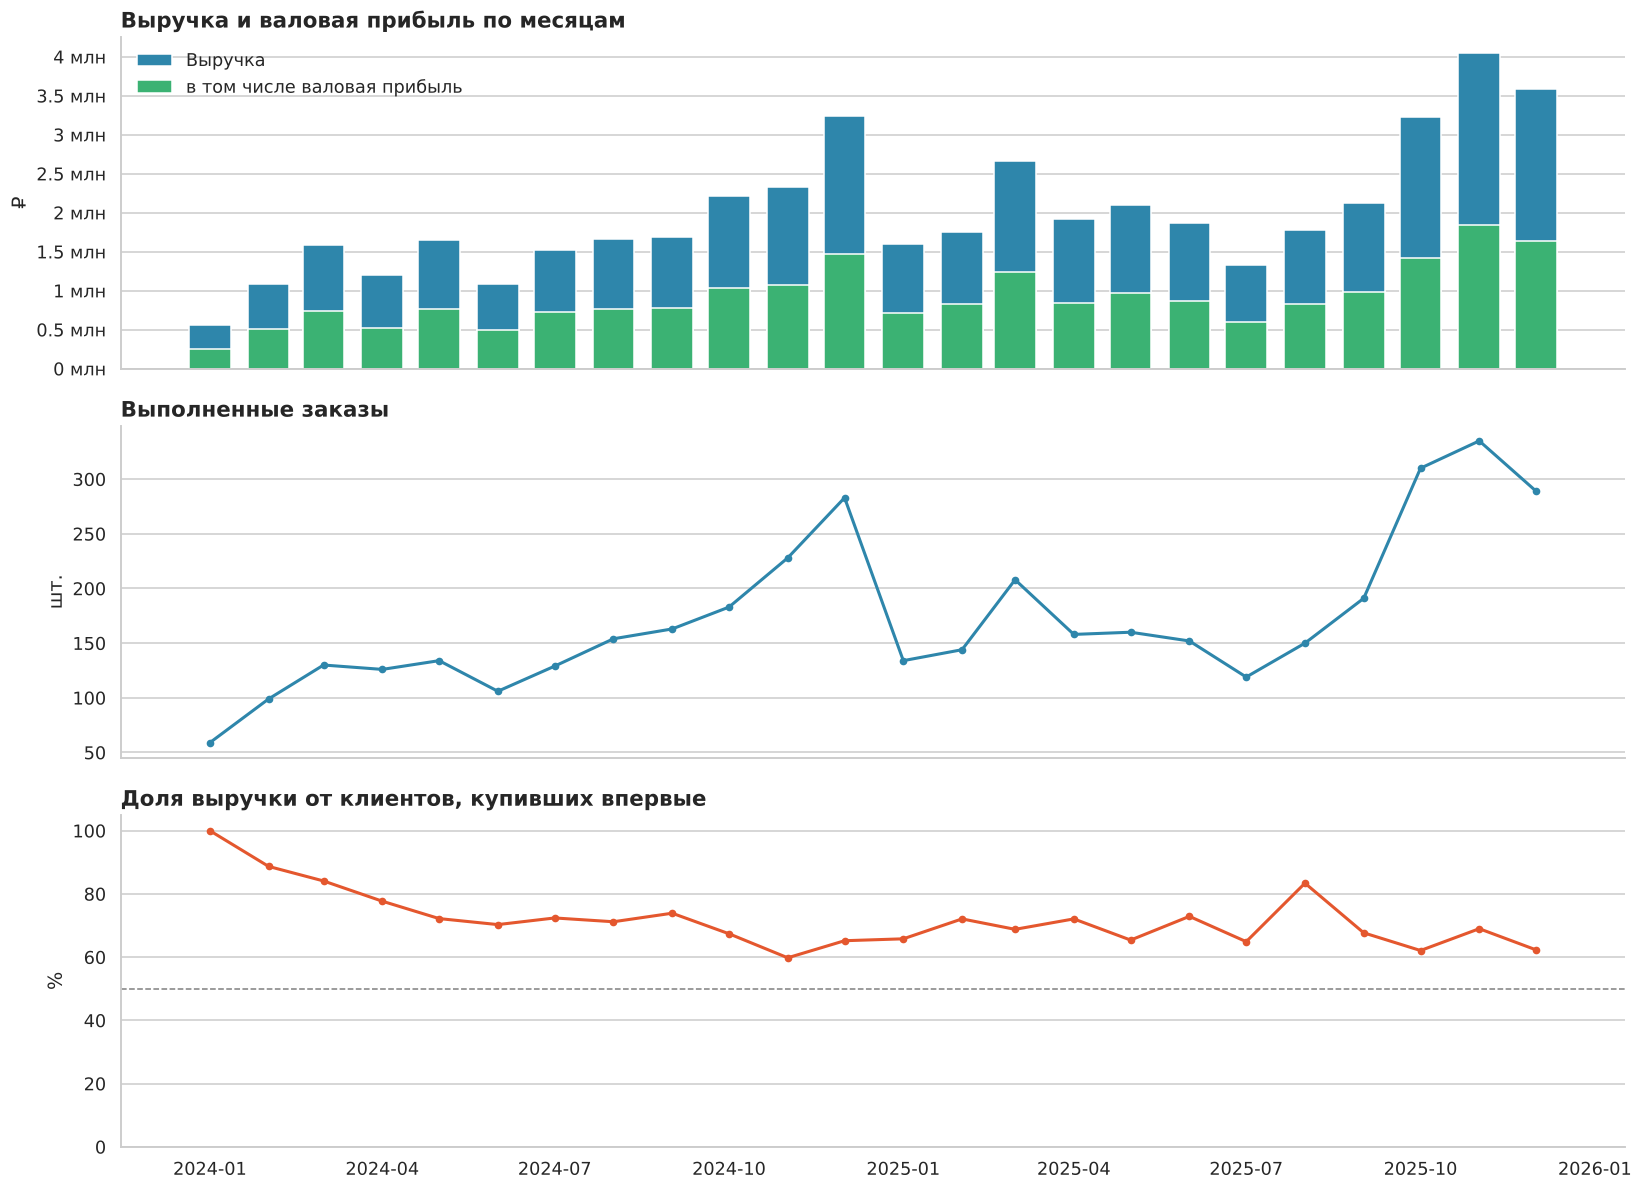

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

ax = axes[0]
ax.bar(metrics['month'], metrics['revenue'], width=22, color=MAIN, label='Выручка')
ax.bar(metrics['month'], metrics['gross_profit'], width=22, color=GOOD,
       label='в том числе валовая прибыль')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set(title='Выручка и валовая прибыль по месяцам', ylabel='₽')
ax.legend(frameon=False, loc='upper left')

ax = axes[1]
ax.plot(metrics['month'], metrics['orders'], color=MAIN, marker='o', markersize=4, linewidth=2)
ax.set(title='Выполненные заказы', ylabel='шт.')

ax = axes[2]
ax.plot(metrics['month'], metrics['new_revenue_share'], color=ACCENT,
        marker='o', markersize=4, linewidth=2)
ax.axhline(50, color='grey', linestyle='--', linewidth=1)
ax.set(title='Доля выручки от клиентов, купивших впервые', ylabel='%', ylim=(0, 105))

for ax in axes:
    ax.grid(axis='x', visible=False)

fig.tight_layout()
save_fig(fig, 'revenue_dynamics.png')
plt.show()

In [10]:
first_year = metrics[metrics['month'].dt.year == metrics['month'].dt.year.min()]
last_year = metrics[metrics['month'].dt.year == metrics['month'].dt.year.max()]

pd.DataFrame({
    'выручка, ₽': [first_year['revenue'].sum(), last_year['revenue'].sum()],
    'заказы': [first_year['orders'].sum(), last_year['orders'].sum()],
    'средний чек, ₽': [first_year['revenue'].sum() / first_year['orders'].sum(),
                       last_year['revenue'].sum() / last_year['orders'].sum()],
    'доля новых в выручке, %': [first_year['new_revenue_share'].mean(),
                                last_year['new_revenue_share'].mean()],
}, index=[str(first_year['month'].dt.year.iloc[0]), str(last_year['month'].dt.year.iloc[0])]).round(1)

,"выручка, ₽",заказы,"средний чек, ₽","доля новых в выручке, %"
2024,19 832 726.00,1794,11 055.00,75.20
2025,28 001 143.00,2350,11 915.40,68.90


**Выводы**

- Выручка растёт, валовая маржа держится около 45% и в течение периода почти не меняется.
- В спросе видна сезонность: пик приходится на ноябрь–декабрь, провал — на январь и июль.
- Повторные покупки делает лишь каждый третий покупатель, в среднем на клиента приходится
  около 1,5 заказа.
- Доля выручки от клиентов, купивших впервые, остаётся очень высокой. Рост держится на постоянном
  притоке новых клиентов, а не на возврате старых. Это дорогая модель роста: как только расходы на
  привлечение перестанут увеличиваться, выручка остановится.

## 4. Когортный анализ удержания

Группируем клиентов по месяцу первой покупки и смотрим, какая доля когорты возвращается
в следующие месяцы. Запрос — [`sql/05_cohort_retention.sql`](../sql/05_cohort_retention.sql).

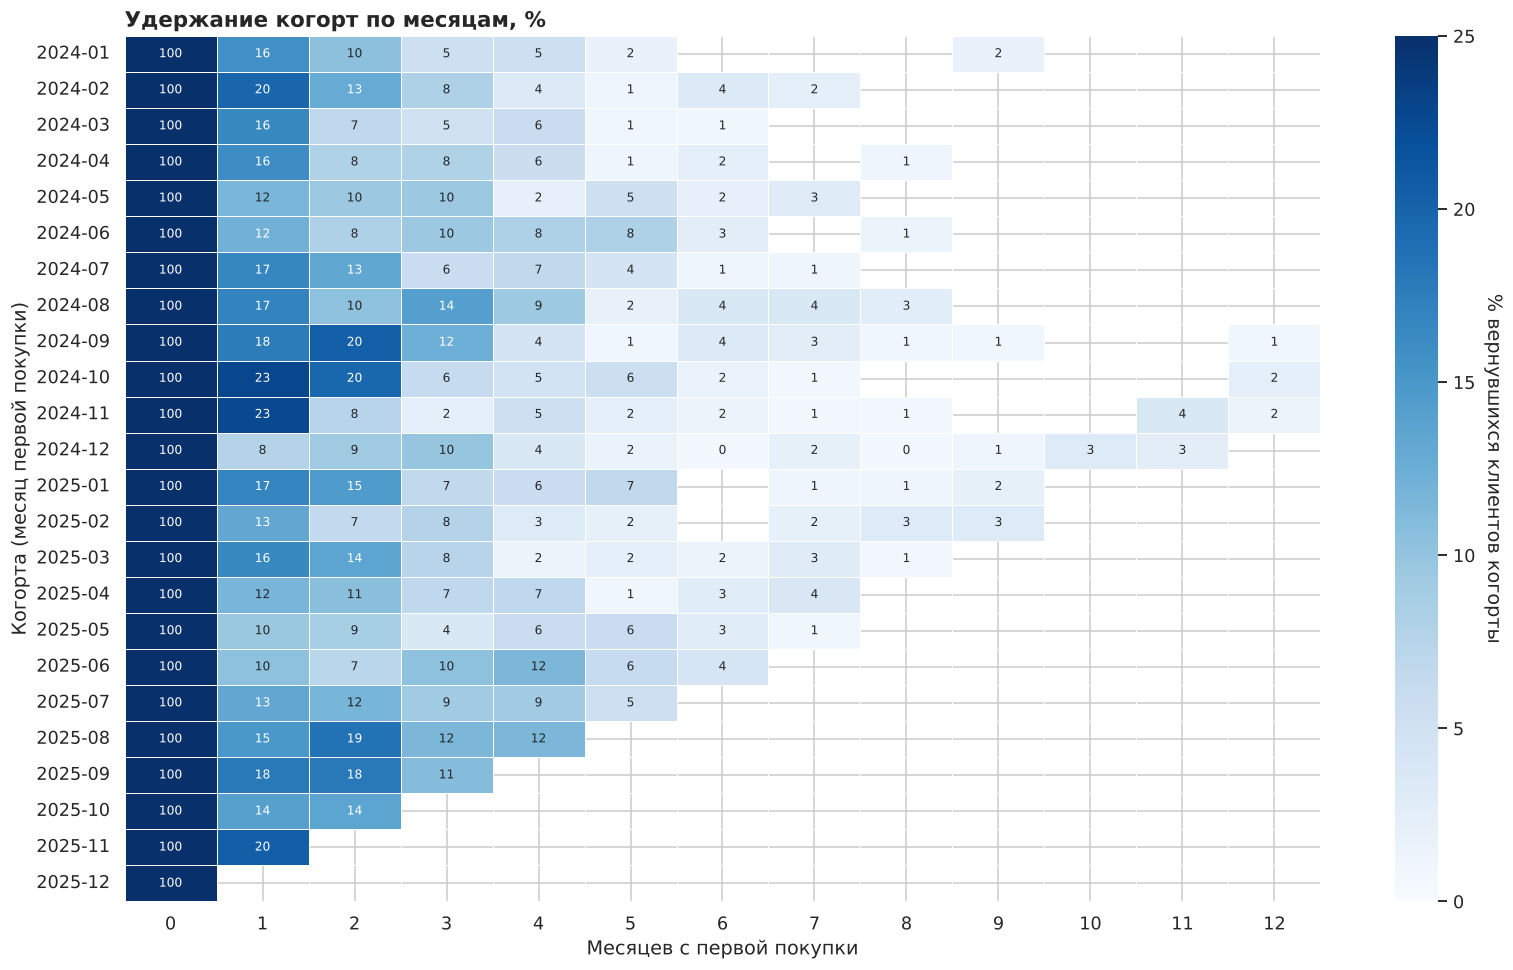

In [11]:
cohorts = run_sql_file('05_cohort_retention.sql', engine)
cohorts = to_float(cohorts, 'retention_pct', 'revenue', 'revenue_per_customer')
retention = cohorts.pivot(index='cohort_month', columns='period_number', values='retention_pct')

# Для наглядности показываем первый год жизни когорты
retention_plot = retention.loc[:, :12]

fig, ax = plt.subplots(figsize=(15, 9))
sns.heatmap(retention_plot, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=25,
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': '% вернувшихся клиентов когорты'},
            annot_kws={'fontsize': 8}, ax=ax)
ax.figure.axes[-1].yaxis.label.set_rotation(270)
ax.figure.axes[-1].yaxis.labelpad = 18
ax.set(title='Удержание когорт по месяцам, %',
       xlabel='Месяцев с первой покупки', ylabel='Когорта (месяц первой покупки)')
fig.tight_layout()
save_fig(fig, 'cohort_retention.png')
plt.show()

Усреднённая кривая удержания по всем когортам:

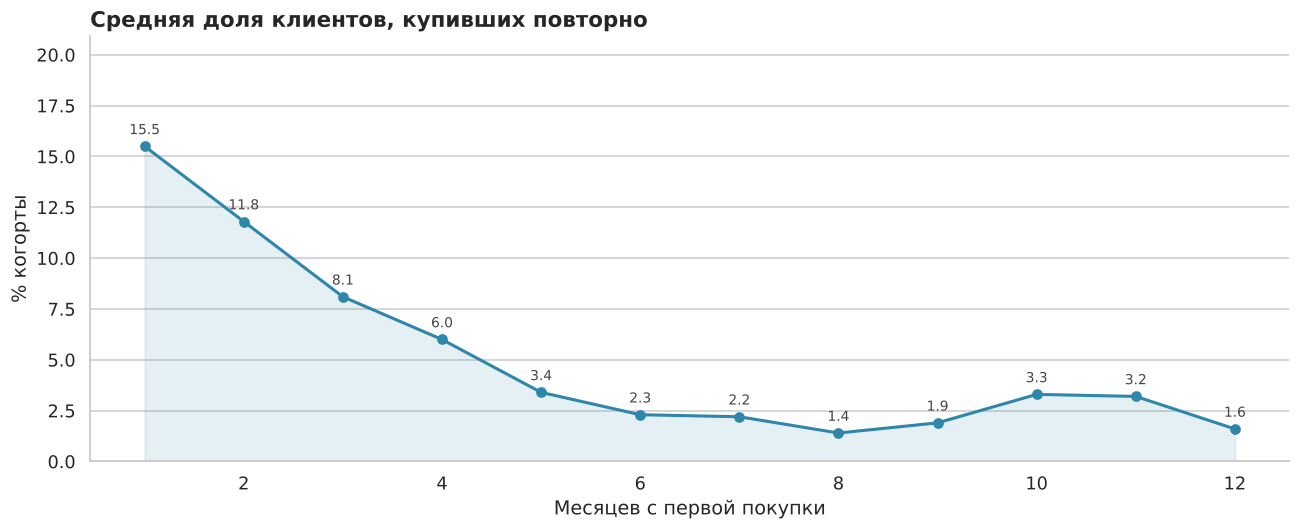

period_number,1,2,3,4,5,6,7,8,9,10,11,12
retention_pct,15.50,11.80,8.10,6.00,3.40,2.30,2.20,1.40,1.90,3.30,3.20,1.60


In [12]:
curve = retention.loc[:, 1:12].mean().round(1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(curve.index, curve.values, color=MAIN, marker='o', linewidth=2)
ax.fill_between(curve.index, curve.values, color=MAIN, alpha=0.12)
for x, y in curve.items():
    ax.annotate(f'{y:.1f}', (x, y), textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=9, color='#444')
ax.set(title='Средняя доля клиентов, купивших повторно',
       xlabel='Месяцев с первой покупки', ylabel='% когорты', ylim=(0, curve.max() * 1.35))
ax.grid(axis='x', visible=False)
fig.tight_layout()
save_fig(fig, 'retention_curve.png')
plt.show()

curve.to_frame('retention_pct').T

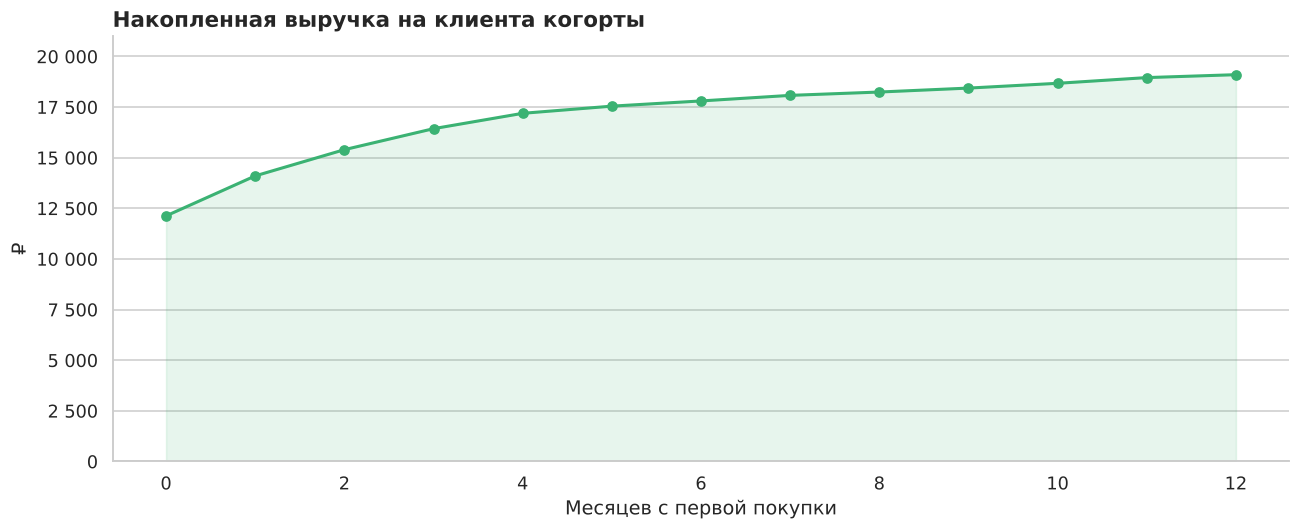

Выручка на клиента за первый месяц: 12 128 ₽
Выручка на клиента за 12 месяцев:   19 101 ₽


In [13]:
# Накопленная выручка на одного клиента когорты: сколько денег приносит клиент со временем
ltv_curve = (cohorts.pivot(index='cohort_month', columns='period_number',
                           values='revenue_per_customer')
             .loc[:, :12]
             .mean()
             .cumsum()
             .round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ltv_curve.index, ltv_curve.values, color=GOOD, marker='o', linewidth=2)
ax.fill_between(ltv_curve.index, ltv_curve.values, color=GOOD, alpha=0.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.set(title='Накопленная выручка на клиента когорты',
       xlabel='Месяцев с первой покупки', ylabel='₽',
       ylim=(0, ltv_curve.max() * 1.1))
ax.grid(axis='x', visible=False)
fig.tight_layout()
save_fig(fig, 'ltv_curve.png')
plt.show()

print(f'Выручка на клиента за первый месяц: {ltv_curve.iloc[0]:,.0f} ₽'.replace(',', ' '))
print(f'Выручка на клиента за 12 месяцев:   {ltv_curve.iloc[-1]:,.0f} ₽'.replace(',', ' '))

**Выводы**

- Удержание резко падает уже на первом месяце: возвращается около 15% когорты, к третьему месяцу
  остаётся менее 10%, к полугоду — около 2%.
- Заметных различий между когортами нет: более поздние когорты ведут себя так же, как ранние.
  Значит, дело не в конкретной рекламной кампании или сезоне, а в самом продукте и работе с базой.
- Основная часть выручки с клиента приходит в первый месяц. Дальше кривая почти плоская —
  магазин зарабатывает на первой покупке, а не на жизненном цикле клиента.

## 5. RFM-сегментация

Делим клиентов по давности покупки (Recency), частоте (Frequency) и сумме (Monetary).
Каждый показатель разбивается на 4 группы через оконную функцию `NTILE`, после чего клиент
попадает в один из бизнес-сегментов. Запрос — [`sql/06_rfm_segments.sql`](../sql/06_rfm_segments.sql).

In [14]:
rfm = run_sql_file('06_rfm_segments.sql', engine)
rfm = to_float(rfm, 'monetary')
rfm.head()

,customer_id,channel,recency_days,frequency,monetary,r_score,f_score,m_score,segment
0,1011,referral,294,5,128 004.00,2,4,4,В зоне риска
1,2234,email,117,3,120 720.00,3,4,4,Лояльные
2,2026,paid_search,272,3,120 498.00,3,4,4,Лояльные
3,690,email,320,8,102 809.00,2,4,4,В зоне риска
4,563,organic,51,3,101 201.00,4,4,4,Лояльные


In [15]:
segments = (rfm.groupby('segment')
            .agg(clients=('customer_id', 'size'),
                 revenue=('monetary', 'sum'),
                 avg_orders=('frequency', 'mean'),
                 avg_revenue=('monetary', 'mean'),
                 avg_recency=('recency_days', 'mean'))
            .round(1))
segments['clients_pct'] = (segments['clients'] / segments['clients'].sum() * 100).round(1)
segments['revenue_pct'] = (segments['revenue'] / segments['revenue'].sum() * 100).round(1)
segments = segments.sort_values('revenue', ascending=False)
segments[['clients', 'clients_pct', 'revenue', 'revenue_pct',
          'avg_orders', 'avg_revenue', 'avg_recency']]

,clients,clients_pct,revenue,revenue_pct,avg_orders,avg_revenue,avg_recency
segment,,,,,,,
Лояльные,608,22.30,20 101 763.00,42.00,2.10,33 062.10,107.00
В зоне риска,549,20.20,16 415 900.00,34.30,2.00,29 901.50,457.30
Потерянные,728,26.70,5 096 333.00,10.70,1.00,7 000.50,487.10
Новички,634,23.30,4 444 562.00,9.30,1.00,7 010.40,111.70
Стабильные,205,7.50,1 775 339.00,3.70,2.10,8 660.20,245.10


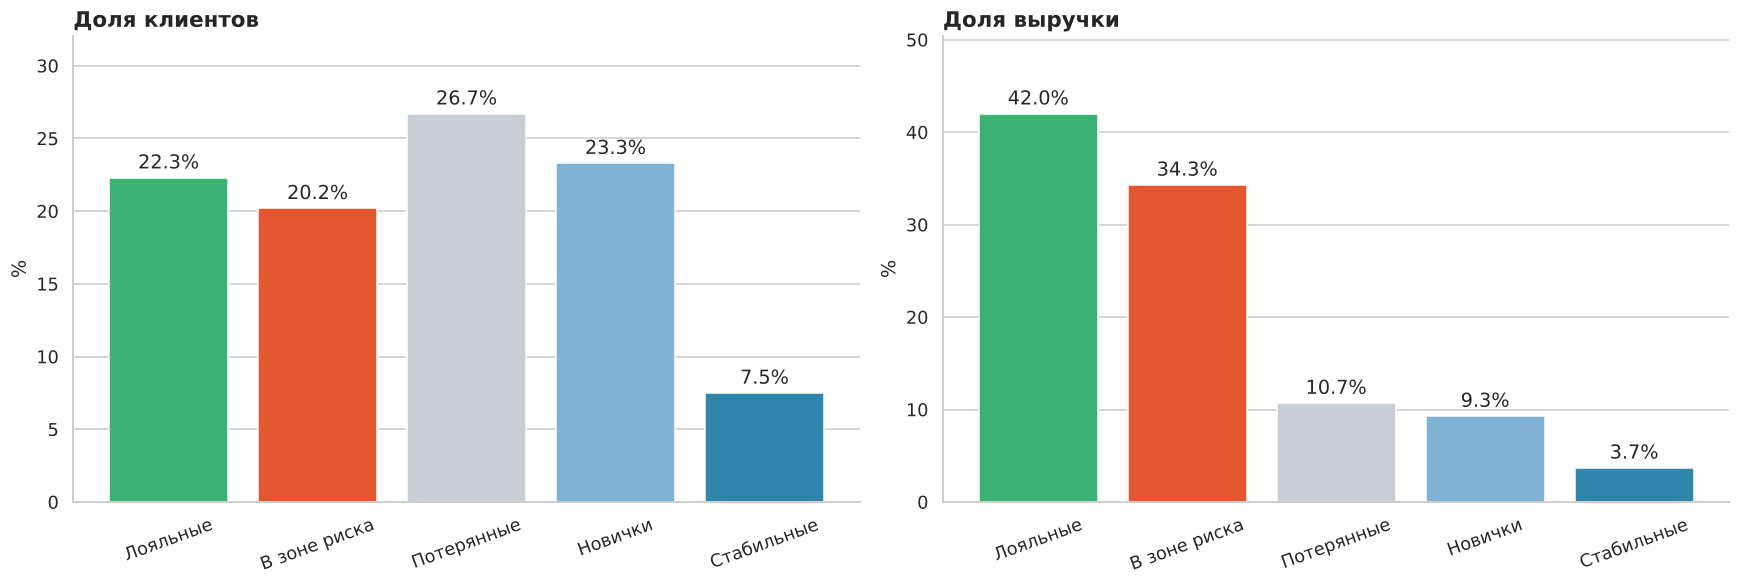

In [16]:
order = segments.index.tolist()
colors = {'Лояльные': GOOD, 'В зоне риска': ACCENT, 'Стабильные': MAIN,
          'Новички': '#7FB3D5', 'Потерянные': MUTED}
palette = [colors.get(s, MAIN) for s in order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

bars = ax1.bar(order, segments['clients_pct'], color=palette)
ax1.bar_label(bars, fmt='%.1f%%', padding=3)
ax1.set(title='Доля клиентов', ylabel='%', ylim=(0, segments['clients_pct'].max() * 1.2))

bars = ax2.bar(order, segments['revenue_pct'], color=palette)
ax2.bar_label(bars, fmt='%.1f%%', padding=3)
ax2.set(title='Доля выручки', ylabel='%', ylim=(0, segments['revenue_pct'].max() * 1.2))

for ax in (ax1, ax2):
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', rotation=20)

fig.tight_layout()
save_fig(fig, 'rfm_segments.png')
plt.show()

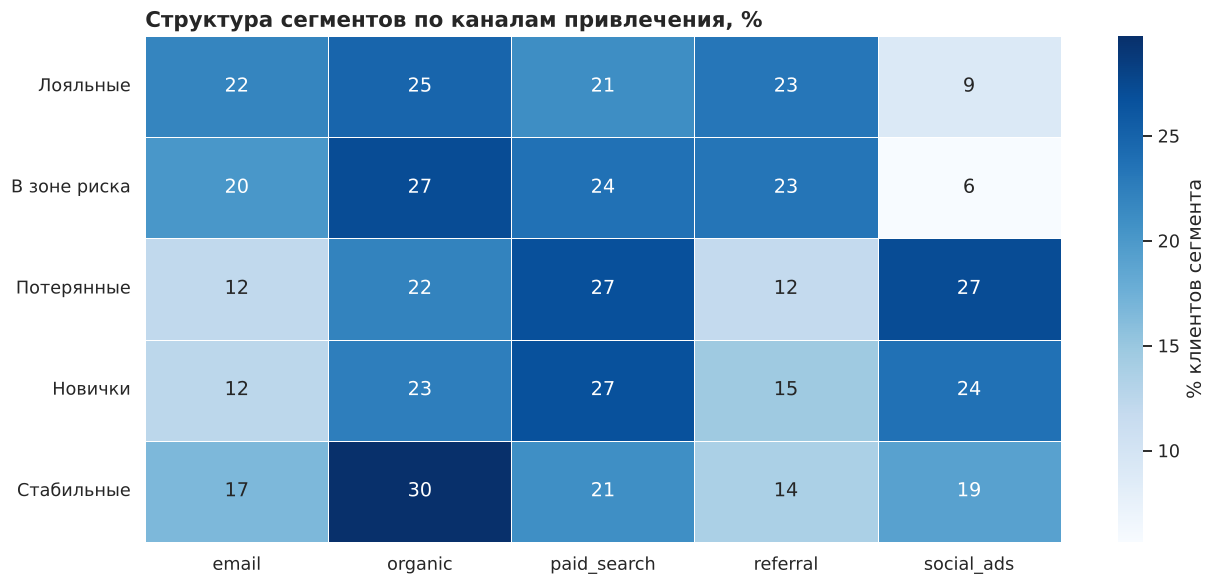

In [17]:
# Из каких каналов приходят клиенты каждого сегмента
channel_mix = pd.crosstab(rfm['segment'], rfm['channel'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(channel_mix.loc[order], annot=True, fmt='.0f', cmap='Blues',
            linewidths=0.5, linecolor='white', cbar_kws={'label': '% клиентов сегмента'}, ax=ax)
ax.set(title='Структура сегментов по каналам привлечения, %', xlabel='', ylabel='')
fig.tight_layout()
save_fig(fig, 'segment_channels.png')
plt.show()

**Выводы**

- «Лояльные» и «В зоне риска» — чуть больше 40% клиентской базы, но на них приходится около
  трёх четвертей всей выручки. Работа с удержанием важнее, чем кажется по размеру этих групп.
- Сегмент «В зоне риска» — клиенты, которые много покупали, но давно не возвращались (в среднем
  больше года назад). Это самая понятная точка роста: их не нужно привлекать заново, достаточно
  напомнить о себе.
- «Потерянные» и «Новички» — половина базы, но лишь около 20% выручки: это разовые покупатели
  с небольшим чеком.
- В сегменте «Потерянные» заметно выше доля платных соцсетей, а среди «Лояльных» — органики,
  рассылки и рекомендаций. Канал привлечения влияет на то, останется ли клиент.

## 6. Экономика каналов привлечения

Сводим расходы на каналы с выручкой и маржой, которую приносят привлечённые клиенты.
Запрос — [`sql/07_channel_economics.sql`](../sql/07_channel_economics.sql).

Важная деталь: стоимость привлечения (CAC) считается на зарегистрированного клиента, поэтому
для сравнения берётся и маржа в расчёте на привлечённого, а не на покупателя. Иначе канал
с низкой конверсией выглядел бы лучше, чем он есть.

In [18]:
channels = run_sql_file('07_channel_economics.sql', engine)
channels = to_float(channels, 'conversion_pct', 'repeat_pct', 'spend', 'cac', 'revenue',
                    'gross_profit', 'ltv_revenue_per_buyer', 'margin_per_acquired',
                    'ltv_cac_ratio', 'net_profit')
channels

,channel,new_customers,buyers,conversion_pct,repeat_pct,spend,cac,revenue,gross_profit,ltv_revenue_per_buyer,margin_per_acquired,ltv_cac_ratio,net_profit
0,organic,921,665,72.20,42.40,204 282.00,222.00,12 213 584.00,5 620 200.00,18 366.00,6 102.00,27.51,5 415 917.00
1,email,569,445,78.20,47.60,222 586.00,391.00,9 628 593.00,4 749 276.00,21 637.00,8 347.00,21.34,4 526 690.00
2,referral,584,476,81.50,47.10,503 292.00,862.00,10 874 949.00,5 625 378.00,22 847.00,9 632.00,11.18,5 122 086.00
3,paid_search,1094,665,60.80,28.10,1 333 164.00,1 219.00,10 218 789.00,4 400 581.00,15 367.00,4 022.00,3.30,3 067 417.00
4,social_ads,1032,473,45.80,15.60,1 662 568.00,1 611.00,4 897 953.00,1 488 633.00,10 355.00,1 442.00,0.90,-173 936.00


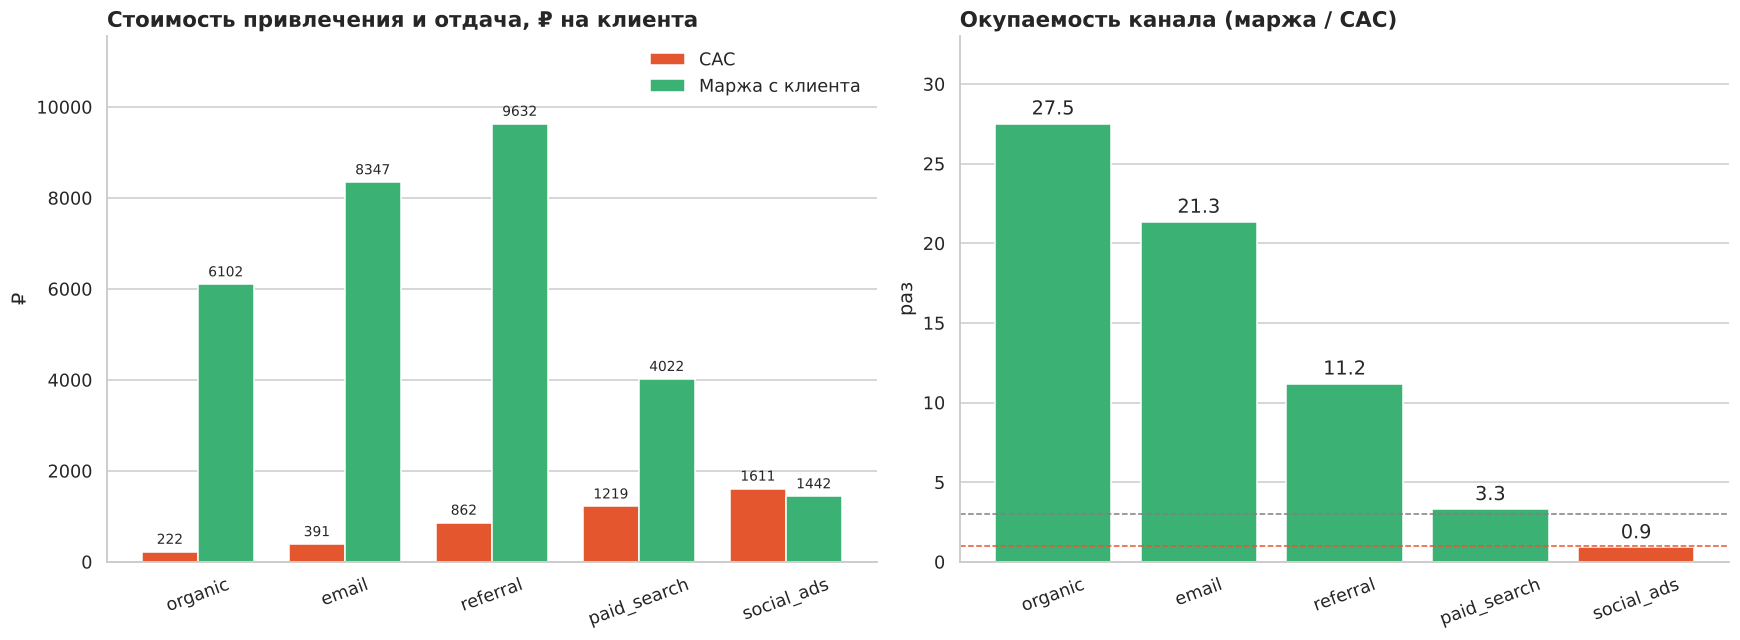

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

x = np.arange(len(channels))
width = 0.38
bars_cac = ax1.bar(x - width / 2, channels['cac'], width, color=ACCENT, label='CAC')
bars_ltv = ax1.bar(x + width / 2, channels['margin_per_acquired'], width,
                   color=GOOD, label='Маржа с клиента')
ax1.bar_label(bars_cac, fmt='%.0f', padding=3, fontsize=9)
ax1.bar_label(bars_ltv, fmt='%.0f', padding=3, fontsize=9)
ax1.set_xticks(x, channels['channel'], rotation=20)
ax1.set(title='Стоимость привлечения и отдача, ₽ на клиента', ylabel='₽')
ax1.set_ylim(top=max(channels['cac'].max(), channels['margin_per_acquired'].max()) * 1.2)
ax1.legend(frameon=False)
ax1.grid(axis='x', visible=False)

ratio_colors = [GOOD if r >= 3 else (MAIN if r >= 1 else ACCENT)
                for r in channels['ltv_cac_ratio']]
bars = ax2.bar(channels['channel'], channels['ltv_cac_ratio'], color=ratio_colors)
ax2.bar_label(bars, fmt='%.1f', padding=3)
ax2.axhline(1, color=ACCENT, linestyle='--', linewidth=1)
ax2.axhline(3, color='grey', linestyle='--', linewidth=1)
ax2.set(title='Окупаемость канала (маржа / CAC)', ylabel='раз')
ax2.set_ylim(top=channels['ltv_cac_ratio'].max() * 1.2)
ax2.tick_params(axis='x', rotation=20)
ax2.grid(axis='x', visible=False)

fig.tight_layout()
save_fig(fig, 'channel_economics.png')
plt.show()

Пунктиром отмечены два ориентира: 1 — канал окупается в ноль, 3 — общепринятый порог
здоровой юнит-экономики.

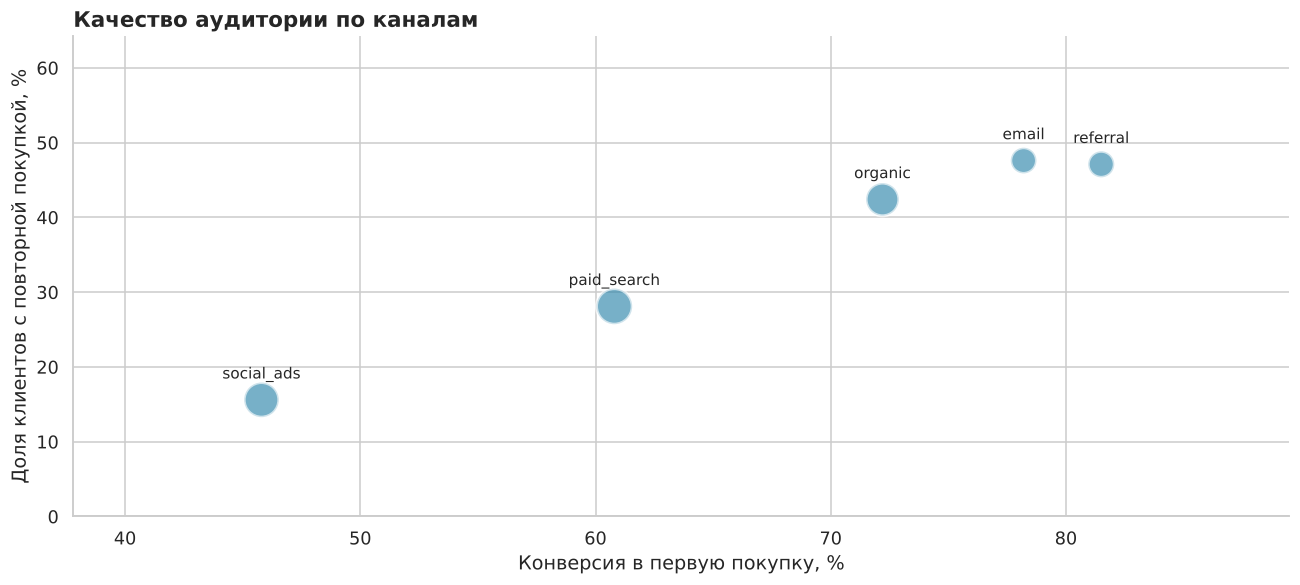

In [20]:
funnel = channels[['channel', 'new_customers', 'conversion_pct', 'repeat_pct',
                   'ltv_revenue_per_buyer']].copy()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(funnel['conversion_pct'], funnel['repeat_pct'],
           s=funnel['new_customers'] / 2, color=MAIN, alpha=0.65, edgecolor='white', linewidth=2)
for row in funnel.itertuples(index=False):
    ax.annotate(row.channel, (row.conversion_pct, row.repeat_pct),
                textcoords='offset points', xytext=(0, 14), ha='center', fontsize=10)
ax.set(title='Качество аудитории по каналам',
       xlabel='Конверсия в первую покупку, %', ylabel='Доля клиентов с повторной покупкой, %')
ax.set_ylim(0, funnel['repeat_pct'].max() * 1.35)
ax.set_xlim(funnel['conversion_pct'].min() - 8, funnel['conversion_pct'].max() + 8)
fig.tight_layout()
save_fig(fig, 'channel_quality.png')
plt.show()

**Выводы**

- Органика, рассылка и рекомендации окупаются многократно: они дёшевы в привлечении и дают
  клиентов, которые возвращаются чаще остальных.
- Платный поиск окупается примерно втрое: это рабочий канал, но без запаса.
- Платные соцсети — единственный убыточный канал. Маржа с привлечённого клиента ниже стоимости
  привлечения, то есть каждый вложенный рубль возвращается не полностью.
- Причина видна на втором графике: у соцсетей самая низкая конверсия в первую покупку и самая
  низкая доля повторных покупок. Канал приводит много людей, но это не целевая аудитория.

In [21]:
# Сколько денег теряется на убыточных каналах
def rub(value):
    return f'{value:,.0f} ₽'.replace(',', ' ')


losing = channels[channels['ltv_cac_ratio'] < 1]
if len(losing):
    for row in losing.itertuples(index=False):
        print(f'{row.channel}: потрачено {rub(row.spend)}, '
              f'получено маржи {rub(row.gross_profit)}, '
              f'итог {rub(row.net_profit)}')
else:
    print('Убыточных каналов нет')

social_ads: потрачено 1 662 568 ₽, получено маржи 1 488 633 ₽, итог -173 936 ₽


## 7. A/B-тест реактивации

Анализ выше показал главную проблему: клиенты почти не возвращаются, а самый перспективный
сегмент — те, кто уже покупал, но давно не возвращался. Проверим на эксперименте, помогает ли
промокод вернуть спящую базу.

### Дизайн эксперимента

| Параметр | Значение |
|---|---|
| Гипотеза | Письмо с промокодом на 10% возвращает спящих клиентов лучше, чем обычная рассылка |
| Участники | Клиенты, зарегистрированные до старта и не покупавшие 90+ дней (включая тех, кто не купил ни разу) |
| Группы | `control` — обычная рассылка, `test` — письмо с промокодом |
| Окно | 2025-10-01 — 2025-11-15 |
| Основная метрика | конверсия в покупку (доля участников, сделавших хотя бы один заказ) |
| Вспомогательные | выручка на участника (ARPU) и маржа на участника |
| Уровень значимости | α = 0,05, двусторонний критерий |

Маржа здесь принципиальна: промокод увеличивает заказы, но уменьшает заработок с каждого.
Если смотреть только на выручку, можно принять убыточное решение.

Данные выгружает [`sql/08_ab_test.sql`](../sql/08_ab_test.sql). Важная деталь: в выгрузку попадают
**все** участники, включая тех, кто ничего не купил. Если оставить только покупателей,
конверсия окажется равной 100%, а выручка на пользователя — завышенной в десятки раз.

In [22]:
from scipy import stats

ab = run_sql_file('08_ab_test.sql', engine)
ab = to_float(ab, 'revenue', 'margin', 'discount')
print(f'Участников эксперимента: {len(ab)}')
ab.head()

Участников эксперимента: 2998


,customer_id,group_name,channel,is_subscribed,orders,converted,revenue,margin,discount
0,4,control,paid_search,0,0,0,0.00,0.00,0.00
1,6,control,email,1,0,0,0.00,0.00,0.00
2,9,control,organic,0,0,0,0.00,0.00,0.00
3,10,control,paid_search,0,0,0,0.00,0.00,0.00
4,11,control,social_ads,1,0,0,0.00,0.00,0.00


### Проверка корректности эксперимента

Прежде чем смотреть на результат, убеждаемся, что эксперимент не сломан. Если разделение
на группы было честным, они должны совпадать по размеру и быть похожими по составу.

In [23]:
control = ab[ab['group_name'] == 'control']
test = ab[ab['group_name'] == 'test']
n_control, n_test = len(control), len(test)

# SRM (Sample Ratio Mismatch): ожидаем деление 50/50
srm = stats.chisquare([n_control, n_test])
print(f'Размер групп: control = {n_control}, test = {n_test}')
print(f'SRM-проверка: p-value = {srm.pvalue:.3f}', end=' ')
print('— деление на группы корректно' if srm.pvalue > 0.01
      else '— ВНИМАНИЕ: группы несбалансированы, результатам доверять нельзя')

# Клиент не должен попасть в обе группы одновременно
assert ab['customer_id'].is_unique, 'Есть клиенты в обеих группах'
print('Пересечений между группами нет')

Размер групп: control = 1487, test = 1511
SRM-проверка: p-value = 0.661 — деление на группы корректно
Пересечений между группами нет


In [24]:
# Группы должны быть похожи по характеристикам, не связанным с экспериментом
balance = pd.DataFrame({
    'control': [control['is_subscribed'].mean() * 100,
                *(control['channel'].value_counts(normalize=True).sort_index() * 100)],
    'test': [test['is_subscribed'].mean() * 100,
             *(test['channel'].value_counts(normalize=True).sort_index() * 100)],
}, index=['Подписаны на рассылку, %',
          *(f'Канал {c}, %' for c in sorted(ab['channel'].unique()))]).round(1)
balance['разница'] = (balance['test'] - balance['control']).round(1)

channel_balance = stats.chi2_contingency(
    pd.crosstab(ab['group_name'], ab['channel'])
)
print(f'Совпадение групп по каналам: p-value = {channel_balance.pvalue:.3f}')
balance

Совпадение групп по каналам: p-value = 0.398


,control,test,разница
"Подписаны на рассылку, %",46.20,46.70,0.50
"Канал email, %",12.60,13.70,1.10
"Канал organic, %",20.70,22.50,1.80
"Канал paid_search, %",27.40,25.70,-1.70
"Канал referral, %",12.40,13.20,0.80
"Канал social_ads, %",26.90,24.90,-2.00


Группы одинаковы по размеру и по составу: различий, которые могли бы объяснить результат
сами по себе, нет. Разделение прошло корректно.

### Чувствительность теста

До разбора результатов полезно понять, какой эффект этот тест вообще способен заметить.
Минимальный детектируемый эффект (MDE) при текущем размере групп:

In [25]:
baseline = control['converted'].mean()
alpha, power = 0.05, 0.80
z_alpha = stats.norm.ppf(1 - alpha / 2)
z_power = stats.norm.ppf(power)

mde = (z_alpha + z_power) * np.sqrt(2 * baseline * (1 - baseline) / n_control)

print(f'Базовая конверсия (control):  {baseline:.2%}')
print(f'MDE при мощности 80%:         {mde:.2%} (абсолютных)')
print(f'То есть тест заметит прирост начиная примерно с {baseline + mde:.2%}')

Базовая конверсия (control):  2.89%
MDE при мощности 80%:         1.72% (абсолютных)
То есть тест заметит прирост начиная примерно с 4.61%


Тест рассчитан только на заметные изменения: прирост меньше примерно 1,7 процентного пункта
он бы не отличил от случайного колебания. Это ограничение — выборка спящей базы фиксирована,
увеличить её можно было бы только продлив эксперимент.

### Результаты

In [26]:
summary = (ab.groupby('group_name')
           .agg(users=('customer_id', 'size'),
                buyers=('converted', 'sum'),
                orders=('orders', 'sum'),
                revenue=('revenue', 'sum'),
                margin=('margin', 'sum')))
summary['conversion_pct'] = (summary['buyers'] / summary['users'] * 100).round(2)
summary['arpu'] = (summary['revenue'] / summary['users']).round(0)
summary['margin_per_user'] = (summary['margin'] / summary['users']).round(0)
summary['avg_check'] = (summary['revenue'] / summary['buyers']).round(0)
summary[['users', 'buyers', 'conversion_pct', 'arpu', 'margin_per_user', 'avg_check']]

,users,buyers,conversion_pct,arpu,margin_per_user,avg_check
group_name,,,,,,
control,1487,43,2.89,283.00,125.00,9 775.00
test,1511,76,5.03,497.00,199.00,9 890.00


**Конверсия.** Сравниваем две доли z-критерием и строим доверительный интервал для разницы.

In [27]:
p_control = control['converted'].mean()
p_test = test['converted'].mean()
diff = p_test - p_control

# z-критерий для разности долей (объединённая оценка дисперсии)
p_pooled = ab['converted'].mean()
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1 / n_control + 1 / n_test))
z_stat = diff / se_pooled
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

# Доверительный интервал строится по раздельной оценке дисперсии
se_diff = np.sqrt(p_control * (1 - p_control) / n_control
                  + p_test * (1 - p_test) / n_test)
ci_low, ci_high = diff - z_alpha * se_diff, diff + z_alpha * se_diff

print(f'Конверсия control: {p_control:.2%}')
print(f'Конверсия test:    {p_test:.2%}')
print(f'Разница:           {diff * 100:+.2f} п.п. '
      f'(относительный прирост {p_test / p_control - 1:+.1%})')
print(f'95% ДИ разницы:    [{ci_low * 100:+.2f}; {ci_high * 100:+.2f}] п.п.')
print(f'z = {z_stat:.2f}, p-value = {p_value:.4f}')
print()
print('Вывод: различие статистически значимо' if p_value < alpha
      else 'Вывод: различие статистически не значимо')

Конверсия control: 2.89%
Конверсия test:    5.03%
Разница:           +2.14 п.п. (относительный прирост +73.9%)
95% ДИ разницы:    [+0.75; +3.53] п.п.
z = 3.00, p-value = 0.0027

Вывод: различие статистически значимо


**Выручка и маржа на участника.** Эти метрики распределены иначе: у большинства участников ноль,
у покупателей — крупные суммы. Такое распределение далеко от нормального, поэтому вместо
t-критерия используем бутстрап: многократно пересобираем выборки и смотрим на распределение
разницы средних.

In [28]:
def bootstrap_diff(control_values, test_values, n_iter=10_000, seed=42):
    """Бутстрап-распределение разницы средних между группами."""
    gen = np.random.default_rng(seed)
    a = np.asarray(control_values)
    b = np.asarray(test_values)
    idx_a = gen.integers(0, len(a), size=(n_iter, len(a)))
    idx_b = gen.integers(0, len(b), size=(n_iter, len(b)))
    return b[idx_b].mean(axis=1) - a[idx_a].mean(axis=1)


results = []
for metric, label in [('revenue', 'Выручка на участника'),
                      ('margin', 'Маржа на участника')]:
    boot = bootstrap_diff(control[metric], test[metric])
    low, high = np.percentile(boot, [2.5, 97.5])
    # Двусторонний p-value: доля бутстрап-выборок по другую сторону от нуля
    p_boot = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    results.append({
        'метрика': label,
        'control': round(control[metric].mean()),
        'test': round(test[metric].mean()),
        'разница': round(boot.mean()),
        'прирост, %': round((test[metric].mean() / control[metric].mean() - 1) * 100, 1),
        '95% ДИ': f'[{low:,.0f}; {high:,.0f}]'.replace(',', ' '),
        'p-value': round(p_boot, 4),
        'значимо': 'да' if p_boot < alpha else 'нет',
    })

bootstrap_results = pd.DataFrame(results)
boot_margin = bootstrap_diff(control['margin'], test['margin'])
boot_revenue = bootstrap_diff(control['revenue'], test['revenue'])
bootstrap_results

,метрика,control,test,разница,"прирост, %",95% ДИ,p-value,значимо
0,Выручка на участника,283,497,215,76.00,[34; 403],0.02,да
1,Маржа на участника,125,199,75,59.80,[-3; 155],0.06,нет


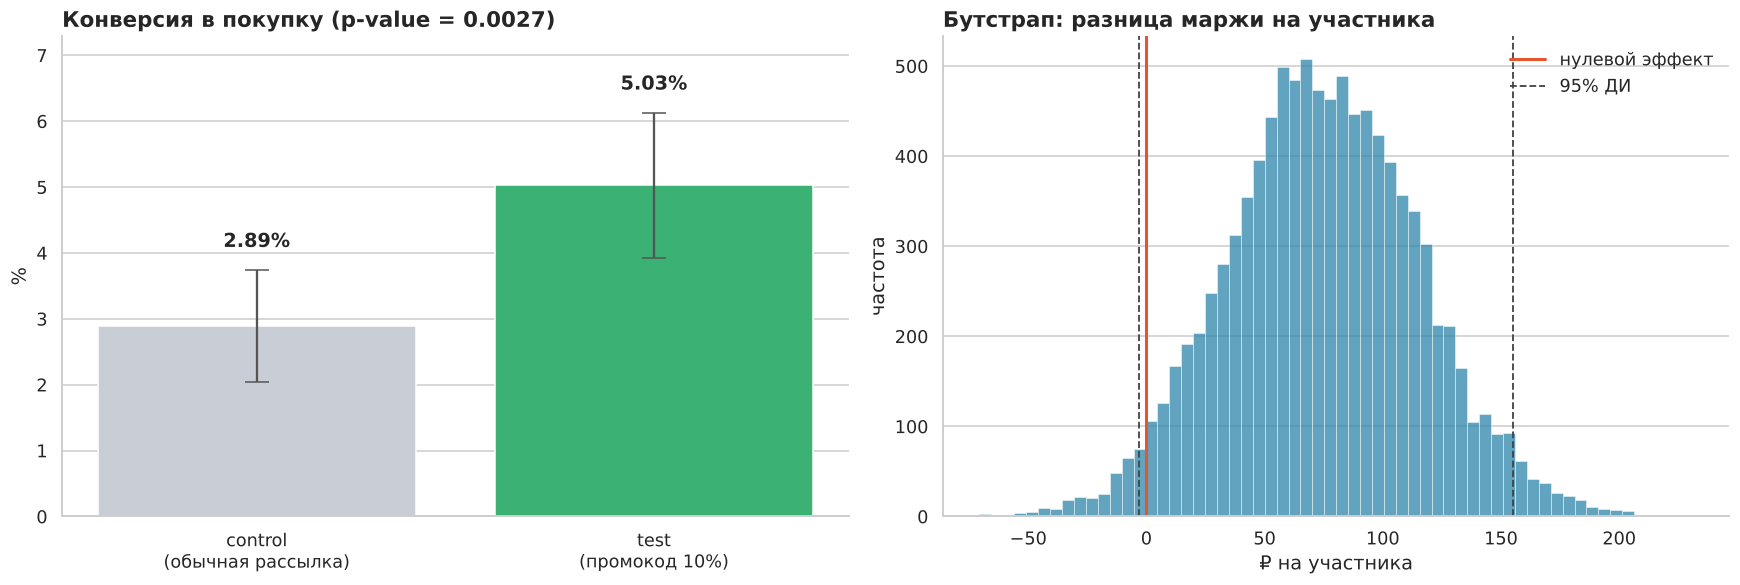

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Конверсия с доверительными интервалами
labels = ['control\n(обычная рассылка)', 'test\n(промокод 10%)']
values = [p_control * 100, p_test * 100]
errors = [z_alpha * np.sqrt(p * (1 - p) / n) * 100
          for p, n in [(p_control, n_control), (p_test, n_test)]]

bars = ax1.bar(labels, values, color=[MUTED, GOOD], yerr=errors, capsize=8,
               error_kw={'ecolor': '#555', 'linewidth': 1.5})
ax1.bar_label(bars, fmt='%.2f%%', padding=12, fontweight='bold')
ax1.set(title=f'Конверсия в покупку (p-value = {p_value:.4f})',
        ylabel='%', ylim=(0, max(values) * 1.45))
ax1.grid(axis='x', visible=False)

# Бутстрап-распределение разницы маржи
ax2.hist(boot_margin, bins=60, color=MAIN, alpha=0.75, edgecolor='white', linewidth=0.4)
low, high = np.percentile(boot_margin, [2.5, 97.5])
ax2.axvline(0, color=ACCENT, linewidth=2, label='нулевой эффект')
ax2.axvline(low, color='#444', linestyle='--', linewidth=1.2, label='95% ДИ')
ax2.axvline(high, color='#444', linestyle='--', linewidth=1.2)
ax2.set(title='Бутстрап: разница маржи на участника',
        xlabel='₽ на участника', ylabel='частота')
ax2.legend(frameon=False)
ax2.grid(axis='x', visible=False)

fig.tight_layout()
save_fig(fig, 'ab_test_results.png')
plt.show()

**Выводы по эксперименту**

- **Конверсия выросла значимо.** Промокод поднял долю вернувшихся клиентов почти в 1,7 раза,
  p-value заметно ниже 0,05. Доверительный интервал не включает ноль, то есть эффект реальный,
  а не случайное колебание.
- **Выручка на участника тоже выросла значимо.** Прирост большой, но доверительный интервал широкий:
  точный размер эффекта по этим данным назвать нельзя, можно уверенно говорить только о направлении.
- **Маржа на участника выросла, но значимость не достигнута.** Правый график показывает, почему:
  распределение разницы смещено в плюс, однако левый край доверительного интервала заходит
  за ноль. Промокод съедает часть прироста, и на таком размере выборки выгода в деньгах
  не доказана.

**Что это значит для бизнеса.** Механика рабочая: клиенты на промокод реагируют. Но принимать
решение только по конверсии нельзя — именно маржа отвечает на вопрос, зарабатывает ли компания.
Разумный следующий шаг: раскатать механику на часть базы и одновременно протестировать более
дешёвые варианты (меньший размер скидки, бесплатная доставка вместо скидки), чтобы сохранить
прирост конверсии и не терять маржу. Для надёжного вывода по марже нужна бóльшая выборка
или более длинное окно наблюдения.

## 8. Выводы и рекомендации

### Что показал анализ

| Область | Результат |
|---|---|
| Качество данных | В выгрузке были дубли заказов, статусы в разном регистре и выбросы в количестве. Без очистки выручка и число заказов оказались бы завышены |
| Рост | Выручка растёт, но почти целиком за счёт новых клиентов: их доля в выручке стабильно высокая |
| Удержание | Повторно покупает около трети клиентов, через полгода активны единицы. Когорты не различаются между собой |
| Сегменты | Треть базы («Лояльные» и «В зоне риска») приносит около трёх четвертей выручки |
| Каналы | Органика, рассылка и рекомендации окупаются многократно, платный поиск — втрое, платные соцсети работают в минус |
| A/B-тест | Промокод значимо поднял конверсию спящей базы и выручку на участника, но прирост маржи статистически не доказан |

### Что с этим делать

1. **Пересобрать бюджет платных соцсетей.** Канал не окупается: деньги уходят на аудиторию,
   которая плохо конвертируется и почти не возвращается. Разумный шаг — сократить расходы и
   перераспределить их в каналы с доказанной окупаемостью, прежде всего в рассылку и реферальную программу.
2. **Заняться сегментом «В зоне риска».** Это клиенты с историей крупных покупок, которые давно
   не возвращались. Реактивация обойдётся дешевле привлечения новых: у магазина уже есть их контакты
   и история заказов. A/B-тест подтвердил, что механика работает, но перед раскаткой стоит
   подобрать вариант стимула, который не съедает маржу.
3. **Поднять повторные покупки.** Основная выручка с клиента приходит в первый месяц, дальше кривая
   плоская. Стоит проверить сценарии второй покупки: напоминание о расходниках, подборки
   к уже купленному, бонус на следующий заказ.
4. **Следить за долей выручки от новых клиентов.** Сейчас рост держится на притоке. Эту долю
   имеет смысл сделать регулярной метрикой: её снижение будет означать, что магазин начал
   зарабатывать на удержании.

### Что можно доделать

- Продлить A/B-тест, чтобы набрать выборку для надёжного вывода по марже, и сравнить
  несколько вариантов стимула.
- Посчитать окупаемость каналов с разбивкой по месяцам, чтобы увидеть срок возврата вложений.
- Построить прогноз оттока: предсказывать, кто из активных клиентов рискует не вернуться.

In [30]:
engine.dispose()
print('Готово. Графики сохранены в папку images/')

Готово. Графики сохранены в папку images/
